# 01 — Dataset Exploration

Points at one dataset root and reports what's actually there before any preprocessing/training code runs. Works two ways:

- **Specialized adapter** (`"brackishmot"`, `"sfishtrack"`): parses the real per-video/sequence structure — frame counts, resolution, class distribution, track counts.
- **Generic scan** (`"mft25"`, `"fathomnet"`, `"noaa"`, `"onc"`, or `"generic"`): a dataset-agnostic file walk (image/video/annotation counts, extensions, sample paths) so you get an honest picture even before that dataset has a real parser. Add `aquatrack/datasets/<name>.py` (see `brackishmot.py`/`sfishtrack.py`) plus an entry in `aquatrack/datasets/explore.py`'s `_ADAPTERS` to bring a new kind online — nothing else in this notebook needs to change.

**Kernel:** **AquaTrack+ (.venv)**.

## Configuration

Set these two values for whichever dataset you're pointing at **here, once** — nothing below this cell should ever hard-code a path. `DATASET_KIND` must be one of `aquatrack.datasets.KNOWN_DATASET_KINDS`.

In [41]:
from aquatrack.datasets import KNOWN_DATASET_KINDS

print("Known dataset kinds:", KNOWN_DATASET_KINDS)

# --- Edit these two lines for your dataset, then Run All --------------
DATASET_PATH = r"C:\Users\oyele\Downloads\SFISHTRACK\SFISHTRACK"
DATASET_KIND = "sfishtrack"
# Other real datasets on this machine — swap in as needed:
#   DATASET_PATH = r"C:\Users\oyele\Downloads\archive\BrackishMOT"; DATASET_KIND = "brackishmot"
# ------------------------------------------------------------------------

Known dataset kinds: ('brackishmot', 'sfishtrack', 'mft25', 'fathomnet', 'noaa', 'onc', 'generic')


In [42]:
from pathlib import Path

dataset_path = Path(DATASET_PATH)
assert dataset_path.is_dir(), f"DATASET_PATH does not exist or is not a directory: {dataset_path}"
print(f"Exploring {DATASET_KIND!r} at {dataset_path.resolve()}")

Exploring 'sfishtrack' at C:\Users\oyele\Downloads\SFISHTRACK\SFISHTRACK


## Explore

In [43]:
from aquatrack.datasets import explore_dataset

report = explore_dataset(dataset_path, kind=DATASET_KIND)
report.get("note")  # only present for the generic-scan path

## Specialized view (BrackishMOT: per-sequence, SFISHTRACK: per-video)

Skipped automatically for the generic-scan path (no structured key to build a table from).

In [44]:
import pandas as pd

if "splits" in report:  # brackishmot
    rows = [
        {"group": split, **seq}
        for split, sequences in report["splits"].items()
        for seq in sequences
    ]
elif "videos" in report:  # sfishtrack
    rows = [{"group": DATASET_KIND, **video} for video in report["videos"]]
else:
    rows = []

item_df = pd.DataFrame(rows)
if not item_df.empty:
    display(item_df)
else:
    print("No specialized per-item data for this dataset kind — see the generic scan below.")

,group,name,frames,resolution,annotations,unique_tracks,class_counts,has_video_file,has_masks
0,sfishtrack,video_001,296,1920x1080,551,3,{'fish': 551},True,True
1,sfishtrack,video_002,578,1920x1080,1553,6,{'object': 1553},True,True
2,sfishtrack,video_003,690,1920x1080,7335,35,{'object': 7335},True,True
3,sfishtrack,video_004,330,1920x1080,312,1,{'object': 312},True,True
4,sfishtrack,video_005,394,1920x1080,933,6,{'object': 933},True,True
5,sfishtrack,video_006,521,1920x1080,2047,16,{'object': 2047},True,True
6,sfishtrack,video_007,330,1920x1080,306,2,{'object': 306},True,True
7,sfishtrack,video_008,552,1920x1080,940,7,{'object': 940},True,True
8,sfishtrack,video_009,615,1920x1080,1423,6,{'object': 1423},True,True
9,sfishtrack,video_010,817,1920x1080,1390,12,{'object': 1390},True,True


In [45]:
if not item_df.empty:
    totals = item_df.groupby("group")[["frames", "annotations", "unique_tracks"]].sum()
    display(totals)

,frames,annotations,unique_tracks
group,,,
sfishtrack,23532,147582,968


In [46]:
if not item_df.empty:
    from collections import Counter

    class_totals = Counter()
    for counts in item_df["class_counts"]:
        class_totals.update(counts)
    class_df = pd.DataFrame(
        sorted(class_totals.items(), key=lambda kv: -kv[1]),
        columns=["class", "annotation_count"],
    )
    display(class_df)

,class,annotation_count
0,object,147031
1,fish,551


## Per-video recording metadata (SFISHTRACK only)

SFISHTRACK ships free-text survey metadata per video (date, depth, camera, location) that BrackishMOT doesn't have — real marine-survey context worth surfacing separately rather than forcing into a shared schema the other adapter would just leave empty.

In [47]:
if DATASET_KIND == "sfishtrack":
    from aquatrack.datasets import discover_videos, read_video_annotations, read_video_metadata

    meta_rows = []
    for annotation_path in discover_videos(dataset_path):
        video = read_video_annotations(annotation_path)
        meta_rows.append({"video": video.name, **read_video_metadata(video)})
    display(pd.DataFrame(meta_rows))
else:
    print(f"Skipped — no per-video recording metadata for {DATASET_KIND!r}.")

,video,Date of recording,Depth of recording,camera model,approximate location
0,video_001,22/05/2021,10m,GoPro Hero 3,Palma's bay
1,video_002,22/05/2021,10m,GoPro Hero 3,Palma's bay
2,video_003,22/05/2021,10m,GoPro Hero 3,Palma's bay
3,video_004,22/05/2021,10m,GoPro Hero 3,Palma's bay
4,video_005,22/05/2021,10m,GoPro Hero 3,Palma's bay
5,video_006,22/05/2021,10m,GoPro Hero 3,Palma's bay
6,video_007,22/05/2021,10m,GoPro Hero 3,Palma's bay
7,video_008,22/05/2021,10m,GoPro Hero 3,Palma's bay
8,video_009,22/05/2021,10m,GoPro Hero 3,Palma's bay
9,video_010,22/05/2021,10m,GoPro Hero 3,Palma's bay


## Generic scan view

Applies to every dataset kind — useful as a sanity check independent of whichever specialized parser ran above.

In [48]:
# Always computed fresh with kind="generic" so this section is meaningful
# regardless of which specialized adapter (if any) ran above.
generic = explore_dataset(dataset_path, kind="generic")
for key in ("total_files", "total_dirs", "image_count", "video_count", "annotation_count", "truncated"):
    print(f"{key:>16}: {generic[key]}")

     total_files: 47811
      total_dirs: 113
     image_count: 47647
     video_count: 54
annotation_count: 109
       truncated: False


In [49]:
pd.DataFrame(
    sorted(generic["extension_counts"].items(), key=lambda kv: -kv[1]),
    columns=["extension", "count"],
)

,extension,count
0,.png,35628
1,.jpg,12019
2,.json,108
3,.mp4,54
4,.txt,1
5,.py,1


## Sample frame preview

Renders one sample image, if any were found, so you can eyeball actual data quality (turbidity, lighting, occlusion) alongside the counts above.

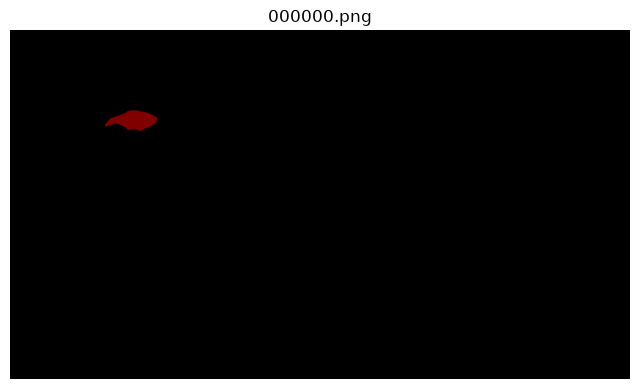

In [50]:
import cv2
import matplotlib.pyplot as plt

sample_images = generic.get("sample_images") or []
if sample_images:
    image = cv2.imread(sample_images[0])
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(8, 6))
    plt.imshow(image_rgb)
    plt.title(Path(sample_images[0]).name)
    plt.axis("off")
    plt.show()
else:
    print("No sample images found by the generic scan (this dataset kind may be video-only, or the scan was truncated).")